# Доверительные интервалы одной доли — два метода

**Практическая записная книжка.** Меняй значения только в **«ВВОД ДАННЫХ»** и нажимай `Run All`.

Два метода из лонгрида Авито: **перебор $p_0$ с инверсией биномиального критерия** и **интервал Уилсона**. Считаем также **одностороннюю нижнюю доверительную границу** и при желании показываем графики.

Работает для `SUCCESSES` успешных независимых испытаний из `N`. Если один пользователь совершает много платежей, не надо бездумно считать их независимыми наблюдениями.

In [1]:
# Импорты — менять не нужно. Файл confidence_intervals.py нужен рядом с ноутбуком.
from confidence_intervals import (
    ci_by_inversion, ci_wilson, plot_confidence_intervals, plot_wilson_coverage,
)
import matplotlib.pyplot as plt

## 1. ВВОД ДАННЫХ — МЕНЯЙ ТОЛЬКО ЭТУ ЯЧЕЙКУ

In [2]:
# ========= ВВОД ДАННЫХ =========
N = 30               # Всего независимых наблюдений
SUCCESSES = 19       # Сколько наблюдений успешные
ALPHA = 0.05         # 0.05 => доверительный уровень 95%
GRID_STEP = 0.001    # Шаг перебора (0.001 = 0.1 п.п.)
SHOW_PLOTS = True    # True = нарисовать графики; False = только результаты
# =================================

## 2. Двусторонние интервалы 95% (или выбранного уровня)
**Что отвечают:** какие значения истинной конверсии совместимы с наблюдёнными данными при соответствующем методе? Интервал НЕ означает 95% вероятность того, что фиксированный параметр попал внутрь него.

In [3]:
ci_grid = ci_by_inversion(SUCCESSES, N, ALPHA, GRID_STEP)
ci_w = ci_wilson(SUCCESSES, N, ALPHA)
print(f"Наблюдаемая конверсия: {SUCCESSES}/{N} = {SUCCESSES/N:.2%}")
print(f"Доверительный уровень: {1-ALPHA:.0%}")
print(f"Перебор гипотез: {ci_grid[0]:.2%} — {ci_grid[1]:.2%}")
print(f"Метод Уилсона:  {ci_w[0]:.2%} — {ci_w[1]:.2%}")

Наблюдаемая конверсия: 19/30 = 63.33%
Доверительный уровень: 95%
Перебор гипотез: 43.90% — 80.00%
Метод Уилсона:  45.51% — 78.13%


## 3. Односторонняя нижняя граница
**Что отвечает:** какова минимальная конверсия, совместимая с наблюдаемыми данными при заданном уровне доверия? Выше границы возможны любые значения до 100%.

In [4]:
lo_grid, _ = ci_by_inversion(SUCCESSES, N, ALPHA, GRID_STEP, side="lower")
lo_w, _ = ci_wilson(SUCCESSES, N, ALPHA, side="lower")
print(f"Перебор: p >= {lo_grid:.2%}")
print(f"Уилсон:  p >= {lo_w:.2%}")

Перебор: p >= 46.70%
Уилсон:  p >= 48.33%


## 4. Графики (необязательно)

**График 1:** все интервалы рядом с наблюдаемой конверсией.

**График 2:** фактическое покрытие интервала Уилсона при разных размерах выборки — идея из исходной лекции. Покрытие рассчитывается суммированием биномиальных вероятностей (без длительной симуляции). Для графика указываем предполагаемую истинную долю равной наблюдаемой; **это иллюстрация**, а не оценка истинного параметра.

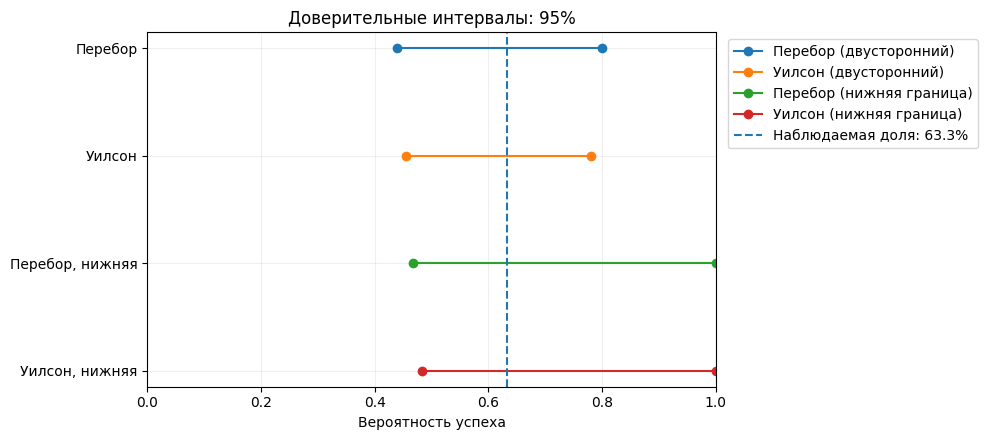

In [5]:
if SHOW_PLOTS:
    fig = plot_confidence_intervals(SUCCESSES, N, ALPHA, GRID_STEP)
    plt.show()
else:
    print("График выключен: SHOW_PLOTS=False")

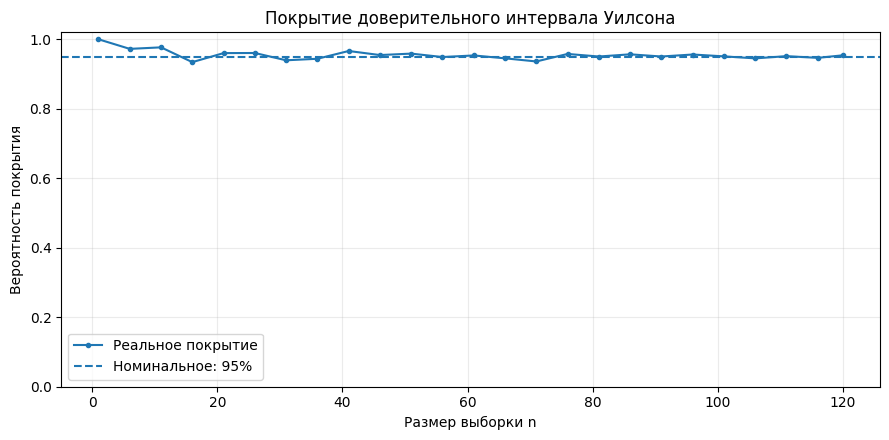

In [6]:
if SHOW_PLOTS:
    fig = plot_wilson_coverage(true_p=SUCCESSES/N, alpha=ALPHA, max_n=120)
    plt.show()
else:
    print("График выключен: SHOW_PLOTS=False")

### Как выбирать метод
- **Перебор:** методически близок к лекции и показывает логику инверсии критерия. Границы на сетке `GRID_STEP`, поэтому вычисление медленнее и результат зависит от шага.
- **Уилсон:** быстрый приближённый интервал одной доли. Реальная вероятность покрытия может колебаться относительно номинального уровня.
- Подробные функции лежат в [`confidence_intervals.py`](./confidence_intervals.py).

Источник: [Avito Tech — Stat power](https://github.com/avito-tech/applied_statistics/blob/main/Stat%20power.ipynb).